## Mismo promedio, distinta historia: la desviacion estándar
Caso de practica (datos ficticios): PARAMANGLA Tiene dos secadoras de cacao. Especificacion del Cliente: Humedad entre 1.2% y 2.0% ¿Las dos secadoras son igual de buenas?

In [1]:
import pandas as pd 
import numpy as np 
import math
import matplotlib.pyplot as plt 

AZUL, AMBAR, ROJO, GRIS = "#1B2B4B", "#D99A2B", "#C0392B", "#9AA7B8"
LIE, LSE = 1.2, 2.0 # Limites de especificacion: inferior y superior

### Carga de la Data

In [2]:
df = pd.read_csv("../data/raw/secadoras.csv")
df

,secadora,lote,humedad
0,A,A01,1.5
1,A,A02,1.6
2,A,A03,1.7
3,A,A04,1.6
4,A,A05,1.5
5,A,A06,1.7
6,A,A07,1.6
7,A,A08,1.6
8,A,A09,1.4
9,A,A10,1.8


### 1. El promedio dice que son iguales

In [3]:
df.groupby("secadora")["humedad"].mean().round(2)

secadora
A    1.6
B    1.6
Name: humedad, dtype: float64

### 2. La desviación estandar dice lo contrario

In [4]:
resumen = (
    df.groupby("secadora")["humedad"]
      .agg(promedio="mean", desviacion="std")
      .round(2)
)
resumen

,promedio,desviacion
secadora,,
A,1.6,0.09
B,1.6,0.34


### 3. Asi se calcula, paso a paso (secadora B)

In [5]:
b = df[df["secadora"] == "B"]["humedad"]
paso = pd.DataFrame({"humedad": b,
                     "distancia": (b - b.mean()).round(2),
                     "distancia²": ((b - b.mean()) ** 2).round(3)})
sigma_b = np.sqrt(paso["distancia²"].sum() / (len(b) - 1))
print("σ calculada a mano:", round(sigma_b, 3), "| con pandas:", round(b.std(), 3))
paso.head(8)

σ calculada a mano: 0.345 | con pandas: 0.345


,humedad,distancia,distancia²
20,1.3,-0.3,0.09
21,2.1,0.5,0.25
22,1.4,-0.2,0.04
23,1.5,-0.1,0.01
24,1.1,-0.5,0.25
25,1.6,0.0,0.00
26,2.3,0.7,0.49
27,1.3,-0.3,0.09


### 4. La diana: donde apuntas y que tan bien disparas

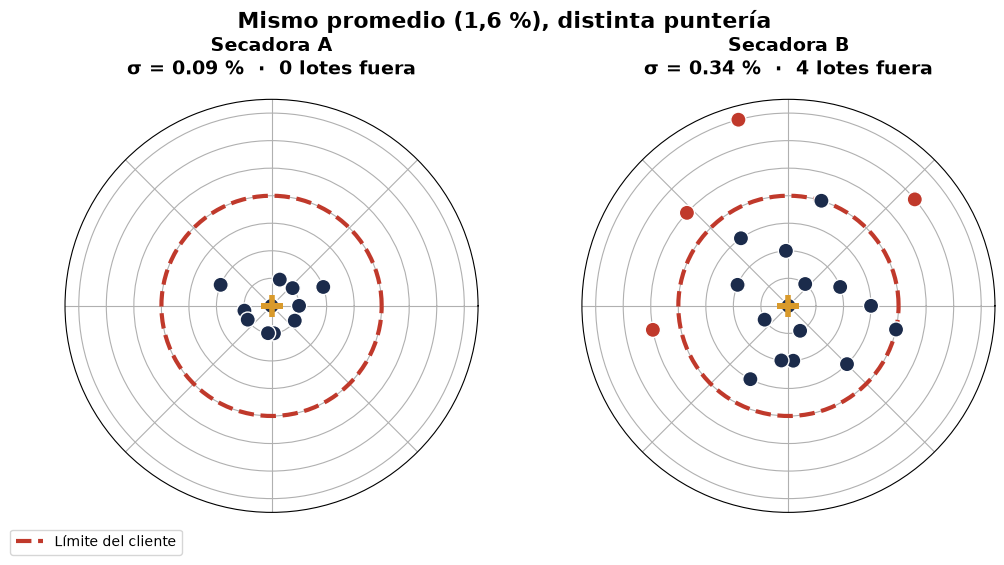

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), subplot_kw={"projection": "polar"})
for ax, (sec, datos) in zip(axes, df.groupby("secadora")):
    dist = (datos["humedad"] - datos["humedad"].mean()).abs()
    ang = np.arange(len(datos)) * 2.39996            # ángulo de oro: reparte los lotes alrededor
    fuera = (datos["humedad"] > LSE) | (datos["humedad"] < LIE)
    ax.scatter(ang, dist, s=120, c=np.where(fuera, ROJO, AZUL), edgecolors="white", zorder=3)
    ax.plot(np.linspace(0, 2 * np.pi, 200), [0.4] * 200, color=ROJO, lw=3, ls="--", label="Límite del cliente")
    ax.scatter(0, 0, s=260, marker="+", color=AMBAR, linewidths=4, zorder=4)
    ax.set_ylim(0, 0.75); ax.set_yticklabels([]); ax.set_xticklabels([])
    ax.set_title(f"Secadora {sec}\nσ = {datos['humedad'].std():.2f} %  ·  {fuera.sum()} lotes fuera", fontsize=14, fontweight="bold", pad=18)
axes[0].legend(loc="lower left", bbox_to_anchor=(-0.15, -0.12))
fig.suptitle("Mismo promedio (1,6 %), distinta puntería", fontsize=16, fontweight="bold")
plt.tight_layout(); plt.savefig("../reports/diana_sigma.png", dpi=200); plt.show()

### 5. La campana: que psara con los proximos lotes?

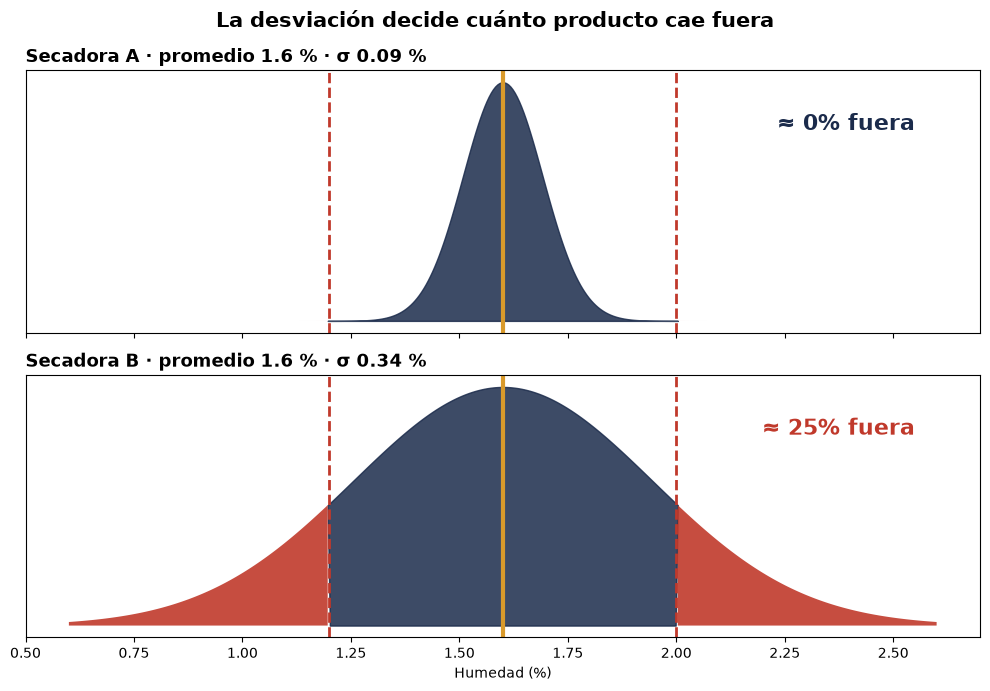

In [7]:
x = np.linspace(0.6, 2.6, 400)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (sec, datos) in zip(axes, df.groupby("secadora")):
    mu, s = datos["humedad"].mean(), datos["humedad"].std()
    y = np.exp(-0.5 * ((x - mu) / s) ** 2) / (s * np.sqrt(2 * np.pi))
    ax.fill_between(x, y, where=(x >= LIE) & (x <= LSE), color=AZUL, alpha=0.85, interpolate=True)
    ax.fill_between(x, y, where=(x < LIE) | (x > LSE), color=ROJO, alpha=0.9, interpolate=True, lw=0)
    fi = lambda z: 0.5 * (1 + math.erf(z / np.sqrt(2)))          # probabilidad acumulada de la normal
    fuera = 1 - (fi((LSE - mu) / s) - fi((LIE - mu) / s))
    ax.text(2.55, y.max() * 0.8, f"≈ {fuera:.0%} fuera", ha="right", fontsize=16, fontweight="bold", color=ROJO if fuera > 0.01 else AZUL)
    for lim in (LIE, LSE):
        ax.axvline(lim, color=ROJO, ls="--", lw=2)
    ax.axvline(mu, color=AMBAR, lw=3)
    ax.set_yticks([]); ax.set_title(f"Secadora {sec} · promedio {mu:.1f} % · σ {s:.2f} %", fontsize=13, fontweight="bold", loc="left")
axes[1].set_xlabel("Humedad (%)")
fig.suptitle("La desviación decide cuánto producto cae fuera", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.savefig("../reports/campana_sigma.png", dpi=200); plt.show()

### 6. Cuantas sigmas caben antes del limite?

In [8]:
cabida = ((LSE - resumen["promedio"]) / resumen["desviacion"]).round(1)
cabida.rename("σ que caben hasta el límite")

secadora
A    4.4
B    1.2
Name: σ que caben hasta el límite, dtype: float64